# Week 03 Lab + Assignment

## From Noise to Financial Data: End-to-End DDPM

**금융AI융합전공 · Diffusion Models**

이번 실습에서는 하나의 Notebook 안에서 다음 전체 과정을 구현합니다.

$$
x_0
\rightarrow
x_t
\rightarrow
\epsilon_\theta(x_t,t)
\rightarrow
\hat{x}_0
\rightarrow
\text{Reverse Diffusion}
\rightarrow
\text{Generated Financial Returns}
$$

이 Notebook은 **실습과 과제를 하나로 통합**합니다.

수업 중 코드를 실행하면서 Diffusion의 핵심 메커니즘을 확인하고,
실습 과정에서 생성되는 결과를 이용하여 과제 질문에 답합니다.

### 핵심 질문

> Gaussian noise에서 시작하여 금융수익률과 유사한 결합분포를
> 어떻게 생성할 수 있는가?

### 제출

완성된 Notebook 한 개를 제출합니다.


## 전체 구성

| Part | 내용 | 핵심 산출물 |
|---|---|---|
| Part 0 | Setup + Financial Data | 2차원 표준화 금융수익률 |
| Part 1 | Forward Diffusion | Theory vs. Empirical |
| Part 2 | Learn the Noise | Noise prediction + reconstruction |
| Part 3 | Reverse Diffusion | Generated financial returns |
| Part 4 | Financial Evaluation | Real vs. Gaussian vs. Diffusion |

### 전체 흐름

$$
\text{Financial Returns}
\rightarrow
\text{Forward Diffusion}
\rightarrow
\text{Noise Prediction}
\rightarrow
\text{Reverse Diffusion}
\rightarrow
\text{Generated Returns}
$$

### 인덱싱 규칙

수학에서는

$$
t=1,\ldots,T
$$

를 사용하지만 Python 배열은 0부터 시작합니다.

따라서

$$
\texttt{alpha\_bars[t-1]}
\quad\leftrightarrow\quad
\bar{\alpha}_t
$$

로 대응합니다.

이 규칙은 전체 Notebook에서 일관되게 사용합니다.


# Part 0. Load Your Real Financial Data

이번 실습에서는 각 학생에게 배정된 **실제 한국 주식 두 종목의 일별 로그수익률 데이터**를 사용합니다.

각 학생은 두 파일을 사용합니다.

1. `Diffusion_week03_lab_assignment.ipynb`
2. 본인에게 배정된 `Diffusion_week03_<학번>_<Pair ID>.csv`

예를 들어 학번 `20186821` 학생이 P01을 배정받았다면 데이터 파일은

`Diffusion_week03_20186821_P01.csv`

입니다.

CSV는 다음 세 열로 구성됩니다.

| Column | 의미 |
|---|---|
| `Date` | 거래일 |
| `Asset_1` | 첫 번째 실제 주식의 일별 로그수익률 |
| `Asset_2` | 두 번째 실제 주식의 일별 로그수익률 |

각 학생에게 서로 다른 주식 pair가 배정되어 있으므로 실행 결과도 학생마다 다릅니다.

## 학습 목적

이번 Week 03의 목적은 주가 데이터 전처리가 아니라 **Diffusion model의 학습과 생성 메커니즘을 이해하는 것**입니다.

따라서 로그수익률은 이미 계산된 상태로 제공합니다.

데이터를 읽은 후 두 수익률을 표준화하여

$$
E[x_0]\approx0,
\qquad
\mathrm{Var}(x_0)\approx1
$$

로 만든 뒤 다음 과정을 수행합니다.

$$
\text{Real Financial Returns}
\rightarrow
\text{Forward Diffusion}
\rightarrow
\epsilon\text{-Prediction}
\rightarrow
\text{Reverse Diffusion}
\rightarrow
\text{Generated Financial Returns}
$$

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 202603

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device :", device)

if torch.cuda.is_available():
    print("GPU    :", torch.cuda.get_device_name(0))


PyTorch: 2.14.0+cpu
Device : cpu


In [2]:
from pathlib import Path
import io
import re
import zipfile

import numpy as np
import pandas as pd
import torch


# ============================================================
# Locate your assigned Week 03 CSV (read directly from the zip)
# ============================================================

MY_STUDENT_ID = "20225085"

zip_candidates = [
    Path("Diffusion_week03_individual.zip"),
    Path("data") / "Diffusion_week03_individual.zip",
]

zip_path = next(
    (p for p in zip_candidates if p.exists()),
    None,
)

if zip_path is None:
    raise FileNotFoundError(
        "Diffusion_week03_individual.zip 파일을 찾을 수 없습니다.\n"
        "zip 파일을 Notebook과 같은 폴더에 두고 다시 실행하세요."
    )

pattern = rf"Diffusion_week03_{MY_STUDENT_ID}_P\d{{2}}\.csv"

with zipfile.ZipFile(zip_path) as zf:
    matched = [
        name
        for name in zf.namelist()
        if re.fullmatch(pattern, Path(name).name)
    ]

    if len(matched) == 0:
        raise FileNotFoundError(
            f"zip 안에서 학번 {MY_STUDENT_ID}의 CSV를 찾을 수 없습니다."
        )

    if len(matched) > 1:
        raise RuntimeError(
            "학번이 같은 CSV가 두 개 이상 발견되었습니다.\n"
            + "\n".join(f"- {name}" for name in matched)
        )

    member_name = matched[0]
    csv_bytes = zf.read(member_name)

data_path = Path(member_name)


# ============================================================
# Student ID and Pair ID
# ============================================================

match = re.fullmatch(
    r"Diffusion_week03_(\d+)_(P\d{2})\.csv",
    data_path.name,
)

if match is None:
    raise ValueError(
        "CSV 파일명이 지정된 형식과 다릅니다: "
        + data_path.name
    )

student_id = match.group(1)
pair_id = match.group(2)


# ============================================================
# Load real daily log returns
# ============================================================

df = pd.read_csv(
    io.BytesIO(csv_bytes),
    parse_dates=["Date"],
)

required_columns = [
    "Date",
    "Asset_1",
    "Asset_2",
]

if list(df.columns) != required_columns:
    raise ValueError(
        "CSV columns must be exactly "
        "Date, Asset_1, Asset_2"
    )

if len(df) != 2631:
    raise ValueError(
        f"Expected 2631 observations, found {len(df)}"
    )

if df["Date"].duplicated().any():
    raise ValueError(
        "Duplicate dates detected."
    )

df = (
    df.sort_values("Date")
    .reset_index(drop=True)
)

returns_raw = (
    df[
        [
            "Asset_1",
            "Asset_2",
        ]
    ]
    .to_numpy(
        dtype=np.float64
    )
)

if not np.isfinite(
    returns_raw
).all():
    raise ValueError(
        "NaN or infinite return detected."
    )


# ============================================================
# Standardization
# ============================================================

mu = returns_raw.mean(
    axis=0
)

sigma = returns_raw.std(
    axis=0,
    ddof=0,
)

if np.any(
    (~np.isfinite(sigma))
    | (sigma <= 0)
):
    raise ValueError(
        "Invalid return standard deviation."
    )

x0_np = (
    returns_raw - mu
) / sigma

x0 = torch.tensor(
    x0_np,
    dtype=torch.float32,
)


# ============================================================
# Sanity checks
# ============================================================

assert x0.shape == (
    2631,
    2,
)

assert np.allclose(
    x0_np.mean(axis=0),
    0.0,
    atol=1e-6,
)

assert np.allclose(
    x0_np.std(
        axis=0,
        ddof=0,
    ),
    1.0,
    atol=1e-6,
)


# ============================================================
# Summary
# ============================================================

print("=" * 60)
print("WEEK 03 REAL FINANCIAL DATA")
print("=" * 60)

print(
    "Student ID :",
    student_id,
)

print(
    "Pair ID    :",
    pair_id,
)

print(
    "Data file  :",
    f"{zip_path.name}/{data_path.name}",
)

print(
    "Period     :",
    df["Date"].min().date(),
    "to",
    df["Date"].max().date(),
)

print(
    "N          :",
    len(df),
)

print()

print(
    "Raw return means:",
    mu,
)

print(
    "Raw return stds :",
    sigma,
)

print()

print(
    "Standardized means:",
    x0.mean(dim=0),
)

print(
    "Standardized stds :",
    x0.std(
        dim=0,
        unbiased=False,
    ),
)

print()

print(
    "Correlation matrix:"
)

print(
    np.corrcoef(
        x0_np.T
    )
)

print()

print(
    "WEEK03_REAL_DATA_LOAD_PASS"
)


WEEK 03 REAL FINANCIAL DATA
Student ID : 20225085
Pair ID    : P06
Data file  : Diffusion_week03_individual.zip/Diffusion_week03_20225085_P06.csv
Period     : 2016-01-04 to 2026-09-23
N          : 2631

Raw return means: [0.00030815 0.00050358]
Raw return stds : [0.02106253 0.02585202]

Standardized means: tensor([ 1.0874e-09, -6.3433e-10])
Standardized stds : tensor([1., 1.])

Correlation matrix:
[[1.         0.75592704]
 [0.75592704 1.        ]]

WEEK03_REAL_DATA_LOAD_PASS


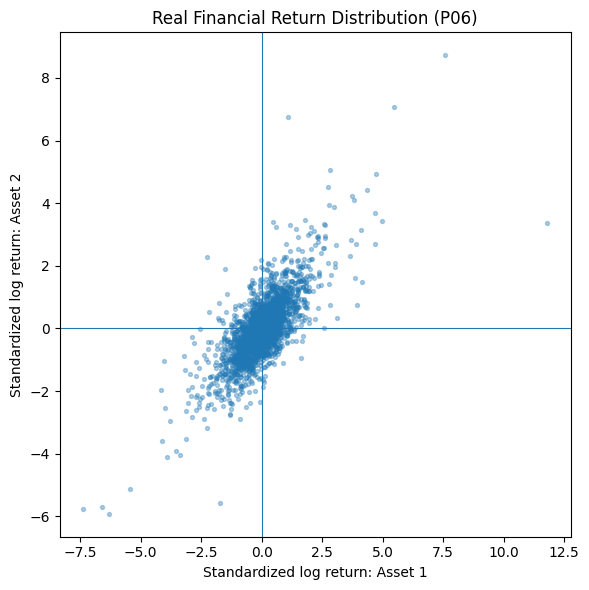

In [3]:
plt.figure(
    figsize=(6, 6)
)

plt.scatter(
    x0_np[:, 0],
    x0_np[:, 1],
    s=8,
    alpha=0.35,
)

plt.axhline(
    0.0,
    linewidth=0.8,
)

plt.axvline(
    0.0,
    linewidth=0.8,
)

plt.xlabel(
    "Standardized log return: Asset 1"
)

plt.ylabel(
    "Standardized log return: Asset 2"
)

plt.title(
    f"Real Financial Return Distribution ({pair_id})"
)

plt.tight_layout()
plt.show()

# Part 1. Forward Diffusion

## 금융수익률 분포를 점차 Gaussian noise로 변환하기

Forward diffusion에서는 원래 데이터 \(x_0\)에 Gaussian noise를
단계적으로 추가합니다.

Linear beta schedule을 사용합니다.

$$
\beta_1,\beta_2,\ldots,\beta_T
$$

그리고

$$
\alpha_t=1-\beta_t
$$

$$
\bar{\alpha}_t
=
\prod_{s=1}^{t}\alpha_s
$$

로 정의합니다.

Forward diffusion의 closed-form 표현은

$$
x_t
=
\sqrt{\bar{\alpha}_t}x_0
+
\sqrt{1-\bar{\alpha}_t}\epsilon,
\qquad
\epsilon\sim N(0,I)
$$

입니다.

여기서 첫 번째 항은 **signal**, 두 번째 항은 **noise**입니다.

$$
\underbrace{
\sqrt{\bar{\alpha}_t}x_0
}_{\text{signal}}
+
\underbrace{
\sqrt{1-\bar{\alpha}_t}\epsilon
}_{\text{noise}}
$$

\(t\)가 증가하면 signal은 감소하고 noise의 비중은 증가합니다.

### 금융 데이터에서 무엇이 사라지는가?

각 자산을 분산 1로 표준화하고 각 차원에 독립적인 Gaussian noise를
추가하면 이론적으로

$$
\mathrm{Var}(x_t)=1
$$

이 유지됩니다.

반면 자산 간 상관관계는

$$
\rho_t
=
\bar{\alpha}_t\rho_0
$$

로 감소합니다.

Excess kurtosis는

$$
\kappa_t
=
\bar{\alpha}_t^2\kappa_0
$$

로 감소합니다.

따라서 forward diffusion은 단순히 데이터의 크기를 변화시키는 것이 아니라
**원래 분포가 가지고 있던 dependence와 non-Gaussian structure를 점차 제거하는 과정**
으로 이해할 수 있습니다.


In [4]:
T = 100
beta_start = 1e-4
beta_end = 0.10

# TODO 1
# betas = beta_start부터 beta_end까지 길이 T의 linear schedule
betas = torch.linspace(beta_start, beta_end, T)

# TODO 2
# alphas = 1 - betas
alphas = 1.0 - betas

# TODO 3
# alpha_bars = alphas의 cumulative product
alpha_bars = torch.cumprod(alphas, dim=0)


In [5]:
assert betas.shape == (T,)
assert alphas.shape == (T,)
assert alpha_bars.shape == (T,)
assert torch.all(alpha_bars[1:] <= alpha_bars[:-1])
assert 0.0 < float(alpha_bars[-1]) < 0.01

print("alpha_bar_1 :", float(alpha_bars[0]))
print("alpha_bar_T :", float(alpha_bars[-1]))
print("FORWARD_SCHEDULE_CHECK_PASS")


alpha_bar_1 : 0.9998999834060669
alpha_bar_T : 0.005618760362267494
FORWARD_SCHEDULE_CHECK_PASS


In [6]:
def extract(values, t, x):
    out = values.to(x.device)[t]
    return out.reshape(-1, 1)


def q_sample(x_start, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x_start)

    # TODO 4
    # sqrt(alpha_bar_t)와 sqrt(1-alpha_bar_t)를 이용해 x_t를 계산하세요.
    sqrt_ab = torch.sqrt(extract(alpha_bars, t, x_start))
    sqrt_1mab = torch.sqrt(1.0 - extract(alpha_bars, t, x_start))
    xt = sqrt_ab * x_start + sqrt_1mab * noise

    return xt, noise


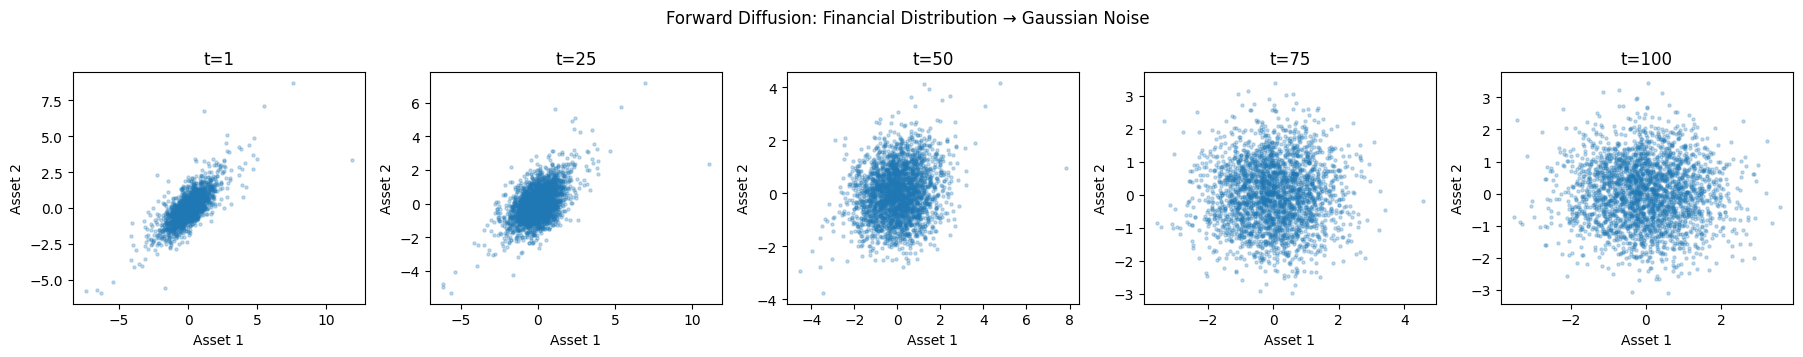

In [7]:
plot_steps = [0, 24, 49, 74, 99]

generator = torch.Generator().manual_seed(SEED + 1)
shared_noise = torch.randn(x0.shape, generator=generator)

fig, axes = plt.subplots(1, len(plot_steps), figsize=(18, 3.6))

for ax, t_value in zip(axes, plot_steps):
    t_batch = torch.full((len(x0),), t_value, dtype=torch.long)
    xt, _ = q_sample(x0, t_batch, shared_noise)

    xt_np = xt.detach().cpu().numpy()

    ax.scatter(xt_np[:, 0], xt_np[:, 1], s=5, alpha=0.25)
    ax.set_title(f"t={t_value + 1}")
    ax.set_xlabel("Asset 1")
    ax.set_ylabel("Asset 2")

fig.suptitle("Forward Diffusion: Financial Distribution → Gaussian Noise")
fig.tight_layout()
plt.show()


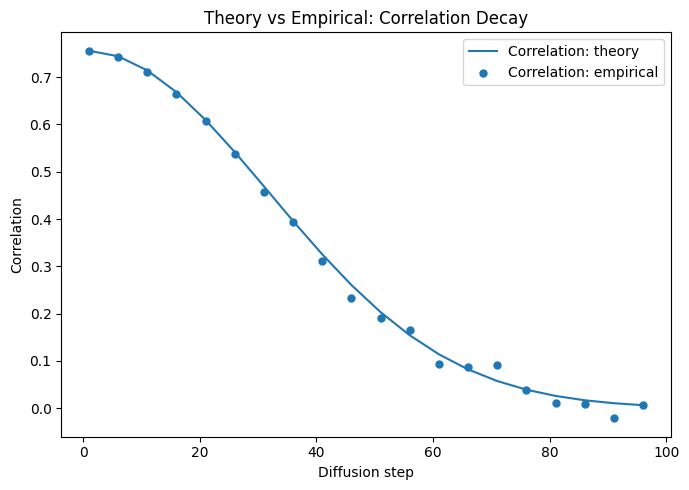

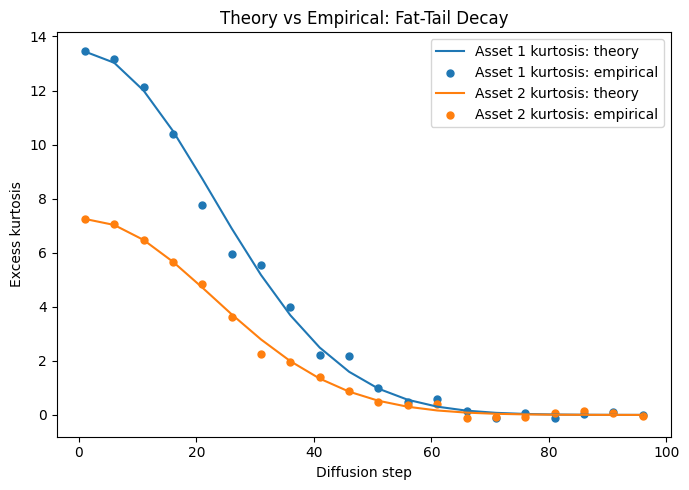

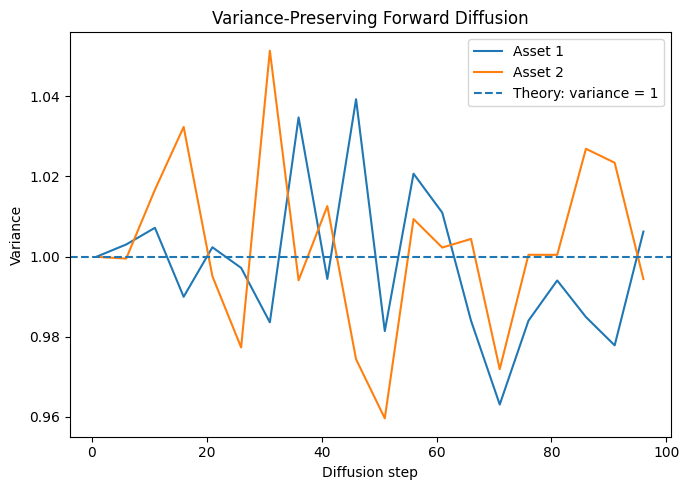

,t,corr_theory,corr_empirical,kurt1_theory,kurt1_empirical,kurt2_theory,kurt2_empirical,var1_empirical,var2_empirical
0,1,0.755851,0.755776,13.443969,13.473747,7.251601,7.252554,1.000052,0.999913
1,6,0.744103,0.743269,13.029274,13.168026,7.027917,7.072054,1.003012,0.999498
2,11,0.714185,0.710942,12.002624,12.117633,6.474147,6.461781,1.007178,1.016679
3,16,0.668212,0.663459,10.507104,10.392680,5.667472,5.655511,0.989951,1.032365
4,21,0.609377,0.608285,8.738304,7.757648,4.713392,4.832016,1.002319,0.995098


In [8]:
def excess_kurtosis(x):
    x = np.asarray(x)
    centered = x - x.mean()
    var = np.mean(centered ** 2)
    return np.mean(centered ** 4) / (var ** 2) - 3.0


eval_steps = np.arange(0, T, 5)

rho0 = np.corrcoef(x0_np.T)[0, 1]
kappa0_1 = excess_kurtosis(x0_np[:, 0])
kappa0_2 = excess_kurtosis(x0_np[:, 1])

empirical_corr = []
empirical_k1 = []
empirical_k2 = []
empirical_var1 = []
empirical_var2 = []

theory_corr = []
theory_k1 = []
theory_k2 = []

eval_generator = torch.Generator().manual_seed(SEED + 2)

for t_value in eval_steps:
    noise = torch.randn(x0.shape, generator=eval_generator)
    t_batch = torch.full((len(x0),), int(t_value), dtype=torch.long)

    xt, _ = q_sample(x0, t_batch, noise)
    arr = xt.detach().cpu().numpy()

    ab = float(alpha_bars[t_value])

    empirical_corr.append(np.corrcoef(arr.T)[0, 1])
    empirical_k1.append(excess_kurtosis(arr[:, 0]))
    empirical_k2.append(excess_kurtosis(arr[:, 1]))
    empirical_var1.append(np.var(arr[:, 0]))
    empirical_var2.append(np.var(arr[:, 1]))

    theory_corr.append(ab * rho0)
    theory_k1.append((ab ** 2) * kappa0_1)
    theory_k2.append((ab ** 2) * kappa0_2)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(eval_steps + 1, theory_corr, label="Correlation: theory")
ax.scatter(eval_steps + 1, empirical_corr, s=25, label="Correlation: empirical")
ax.set_xlabel("Diffusion step")
ax.set_ylabel("Correlation")
ax.set_title("Theory vs Empirical: Correlation Decay")
ax.legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(
    eval_steps + 1,
    theory_k1,
    label="Asset 1 kurtosis: theory",
)
ax.scatter(
    eval_steps + 1,
    empirical_k1,
    s=25,
    label="Asset 1 kurtosis: empirical",
)
ax.plot(
    eval_steps + 1,
    theory_k2,
    label="Asset 2 kurtosis: theory",
)
ax.scatter(
    eval_steps + 1,
    empirical_k2,
    s=25,
    label="Asset 2 kurtosis: empirical",
)
ax.set_xlabel("Diffusion step")
ax.set_ylabel("Excess kurtosis")
ax.set_title("Theory vs Empirical: Fat-Tail Decay")
ax.legend()
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(eval_steps + 1, empirical_var1, label="Asset 1")
ax.plot(eval_steps + 1, empirical_var2, label="Asset 2")
ax.axhline(1.0, linestyle="--", label="Theory: variance = 1")
ax.set_xlabel("Diffusion step")
ax.set_ylabel("Variance")
ax.set_title("Variance-Preserving Forward Diffusion")
ax.legend()
fig.tight_layout()
plt.show()

theory_empirical = pd.DataFrame(
    {
        "t": eval_steps + 1,
        "corr_theory": theory_corr,
        "corr_empirical": empirical_corr,
        "kurt1_theory": theory_k1,
        "kurt1_empirical": empirical_k1,
        "kurt2_theory": theory_k2,
        "kurt2_empirical": empirical_k2,
        "var1_empirical": empirical_var1,
        "var2_empirical": empirical_var2,
    }
)

display(theory_empirical.head())


### Assignment 1 — Theory vs. Empirical

앞에서 얻은 실제 실행 결과를 이용하여 다음 질문에 답하세요.

**Q1-1.** 왜 표준화된 데이터에서는 forward diffusion이 진행되어도
각 자산의 분산이 대략 1을 유지합니까?

힌트:

$$
x_t
=
\sqrt{\bar{\alpha}_t}x_0
+
\sqrt{1-\bar{\alpha}_t}\epsilon
$$

에서 \(x_0\)와 \(\epsilon\)의 분산을 생각해 보세요.

**Q1-2.** 다음 두 식이 금융수익률 분포에서 의미하는 바를 설명하세요.

$$
\rho_t=\bar{\alpha}_t\rho_0
$$

$$
\kappa_t=\bar{\alpha}_t^2\kappa_0
$$

**Q1-3.** 상관관계와 excess kurtosis 가운데 어느 것이 더 빠르게
사라집니까? 자신의 그래프를 근거로 설명하세요.

**[YOUR ANSWER]**

**Q1-1. 분산이 1로 유지되는 이유**

$x_0$는 표준화되어 $\mathrm{Var}(x_0)=1$이고, $\epsilon$은 $N(0,I)$이므로 $\mathrm{Var}(\epsilon)=1$입니다. 두 항은 서로 독립이므로 분산이 그대로 더해집니다.

$$
\mathrm{Var}(x_t)
=
\bar{\alpha}_t\mathrm{Var}(x_0)
+
(1-\bar{\alpha}_t)\mathrm{Var}(\epsilon)
=
\bar{\alpha}_t+(1-\bar{\alpha}_t)
=
1
$$

- 신호의 비중이 줄어드는 만큼 noise의 비중이 늘어나므로 합은 항상 1입니다.
- 실제로 `var1_empirical`, `var2_empirical`이 t=1~21에서 약 0.989~1.032 사이에 있어 이론값 1과 거의 같습니다.

**Q1-2. 두 식의 의미**

- $\rho_t=\bar{\alpha}_t\rho_0$: 두 자산에 서로 독립인 noise를 섞기 때문에 noise는 공통 움직임을 만들지 못하고, 원래의 상관관계만 $\bar{\alpha}_t$ 비율로 줄어듭니다. 즉 diffusion이 진행될수록 두 자산의 동조화(dependence)가 사라집니다. 이번 데이터는 $\rho_0\approx0.756$이었고, t=21에서는 0.609까지 줄었습니다.
- $\kappa_t=\bar{\alpha}_t^2\kappa_0$: Gaussian noise를 섞을수록 분포가 정규분포에 가까워져 fat tail이 사라집니다. 이번 데이터의 초과 첨도는 Asset 1이 13.44, Asset 2가 7.25로 정규분포(0)보다 훨씬 꼬리가 두꺼웠고, t=21에서는 각각 8.74, 4.71로 줄었습니다(이론값 $\bar{\alpha}_t^2\kappa_0$ 기준이며, 실측값은 Q1-3 참고).
- 정리하면 forward diffusion은 데이터의 크기를 바꾸는 것이 아니라, 금융수익률의 **상관구조와 fat tail(비정규성)을 지워 가는 과정**입니다.

**Q1-3. 어느 것이 더 빨리 사라지는가**

- **excess kurtosis가 더 빨리 사라집니다.** 상관관계는 $\bar{\alpha}_t$에 비례하고 첨도는 $\bar{\alpha}_t^2$에 비례하는데, $0<\bar{\alpha}_t<1$이면 $\bar{\alpha}_t^2<\bar{\alpha}_t$이기 때문입니다.
- 표의 t=21에서 비교하면 다음과 같습니다($\bar{\alpha}_{21}\approx0.806$).
  - 상관관계: 0.756 → 0.609, 처음의 약 **81%**가 남았습니다.
  - Asset 1 첨도: 13.44 → 8.74, 약 **65%**가 남았습니다.
  - Asset 2 첨도: 7.25 → 4.71, 약 **65%**가 남았습니다.
- 그래프에서도 Fat-Tail Decay 곡선이 Correlation Decay 곡선보다 더 가파르게 내려갑니다. 두 그래프는 y축 스케일이 달라 기울기만으로는 비교가 어려우므로 후반부 값으로 확인하면, t≈60에서 두 자산의 첨도는 이미 거의 0에 도달했지만($\bar{\alpha}_{61}^2\approx0.02$) 상관관계는 아직 약 0.11(초기값의 약 15%)이 남아 있고, t≈90 무렵에야 0에 가까워집니다(약 0.01). 이론선과 empirical 점이 거의 겹쳐서 공식이 실제 데이터에서도 맞는다는 것을 확인할 수 있습니다.
- 다만 첨도 empirical은 t=21에서 Asset 1이 7.76(Asset 2는 4.83)으로 이론값 8.74(4.71)와 차이가 있는데, 꼬리 극단값 몇 개에 첨도가 민감하게 바뀌는 sampling noise 때문으로 볼 수 있습니다.


# Part 2. Learn the Noise

## Diffusion model은 무엇을 학습하는가?

Diffusion model의 핵심은 원래 데이터 \(x_0\)를 직접 예측하도록
학습하는 것이 아닙니다.

Forward process에서 추가된 noise

$$
\epsilon
$$

을 neural network가 예측하도록 학습합니다.

$$
\epsilon_\theta(x_t,t)
\approx
\epsilon
$$

따라서 학습 목적함수는

$$
\mathcal{L}
=
E\left[
\left\|
\epsilon-
\epsilon_\theta(x_t,t)
\right\|^2
\right]
$$

입니다.

### 왜 timestep \(t\)가 필요한가?

같은 \(x_t\)라도 diffusion 초기인지 마지막인지에 따라 포함된 noise의
수준이 다릅니다.

따라서 neural network에는

$$
(x_t,t)
$$

를 함께 입력해야 합니다.

이번 실습에서는 sinusoidal time embedding을 이용하여
\(t\) 정보를 neural network에 전달합니다.

### 오늘의 핵심 메시지

> **Diffusion model은 데이터를 직접 그리는 방법을 배우는 것이 아니라,
> 각 noise level에서 어떤 noise를 제거해야 하는지를 학습한다.**


In [9]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim=32):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2

        frequencies = torch.exp(
            -np.log(10000)
            * torch.arange(
                half,
                device=t.device,
                dtype=torch.float32,
            )
            / max(half - 1, 1)
        )

        angles = t.float().unsqueeze(1) * frequencies.unsqueeze(0)

        return torch.cat(
            [torch.sin(angles), torch.cos(angles)],
            dim=1,
        )


class NoisePredictor(nn.Module):
    def __init__(self, time_dim=32, hidden_dim=128):
        super().__init__()

        self.time_embedding = SinusoidalTimeEmbedding(time_dim)

        self.net = nn.Sequential(
            nn.Linear(2 + time_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, 2),
        )

    def forward(self, x, t):
        t_emb = self.time_embedding(t)
        h = torch.cat([x, t_emb], dim=1)
        return self.net(h)


model = NoisePredictor().to(device)

n_params = sum(p.numel() for p in model.parameters())

print(model)
print("Trainable parameters:", n_params)


NoisePredictor(
  (time_embedding): SinusoidalTimeEmbedding()
  (net): Sequential(
    (0): Linear(in_features=34, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)
Trainable parameters: 21250


In [10]:
x_train = x0.to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
)

batch_size = 256
n_steps = 2500

losses = []

model.train()

for step in range(n_steps):
    idx = torch.randint(
        0,
        len(x_train),
        (batch_size,),
        device=device,
    )

    x_batch = x_train[idx]

    # TODO 5
    # 각 observation에 대해 random timestep을 뽑으세요.
    t = torch.randint(0, T, (batch_size,), device=device)

    # TODO 6
    # x_batch와 같은 shape의 Gaussian noise를 생성하세요.
    noise = torch.randn_like(x_batch)

    # TODO 7
    # q_sample을 사용하여 x_t를 생성하세요.
    xt, _ = q_sample(x_batch, t, noise)

    # TODO 8
    # model로 noise를 예측하세요.
    pred_noise = model(xt, t)

    # TODO 9
    # true noise와 predicted noise 사이의 MSE를 계산하세요.
    loss = F.mse_loss(pred_noise, noise)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(float(loss.detach().cpu()))

    if (step + 1) % 500 == 0:
        print(
            f"step={step + 1:4d} "
            f"loss={losses[-1]:.6f}"
        )


step= 500 loss=0.358899
step=1000 loss=0.367761
step=1500 loss=0.350044
step=2000 loss=0.373946
step=2500 loss=0.353999


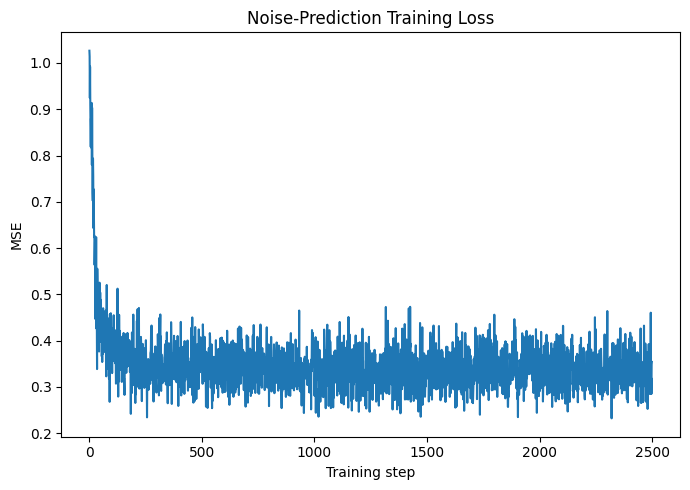

Initial mean loss: 0.5193180242180824
Final mean loss  : 0.3326162114739418


In [11]:
plt.figure(figsize=(7, 5))
plt.plot(losses)
plt.xlabel("Training step")
plt.ylabel("MSE")
plt.title("Noise-Prediction Training Loss")
plt.tight_layout()
plt.show()

print("Initial mean loss:", np.mean(losses[:100]))
print("Final mean loss  :", np.mean(losses[-100:]))


## One-Step Reconstruction

Noise predictor가 실제로 무엇을 학습했는지 확인하기 위해
\(x_t\)에서 원래 \(x_0\)를 직접 추정해 봅니다.

Forward equation

$$
x_t
=
\sqrt{\bar{\alpha}_t}x_0
+
\sqrt{1-\bar{\alpha}_t}\epsilon
$$

을 \(x_0\)에 대해 정리하면

$$
\hat{x}_0
=
\frac{
x_t
-
\sqrt{1-\bar{\alpha}_t}
\epsilon_\theta(x_t,t)
}{
\sqrt{\bar{\alpha}_t}
}
$$

를 얻습니다.

이것은 full reverse diffusion이 아니라
**하나의 \(x_t\)에서 원래 관측치 \(x_0\)를 추정하는 진단 방법**입니다.

\(t\)가 커질수록 \(x_t\) 안에 남아 있는 원래 데이터 정보가 감소하므로
복원이 어려워집니다.


In [12]:
@torch.no_grad()
def reconstruct_x0(model, xt, t):
    pred_noise = model(xt, t)

    sqrt_ab = torch.sqrt(
        extract(alpha_bars, t, xt)
    )

    sqrt_1mab = torch.sqrt(
        1.0 - extract(alpha_bars, t, xt)
    )

    # TODO 10
    x0_hat = (xt - sqrt_1mab * pred_noise) / sqrt_ab

    return x0_hat


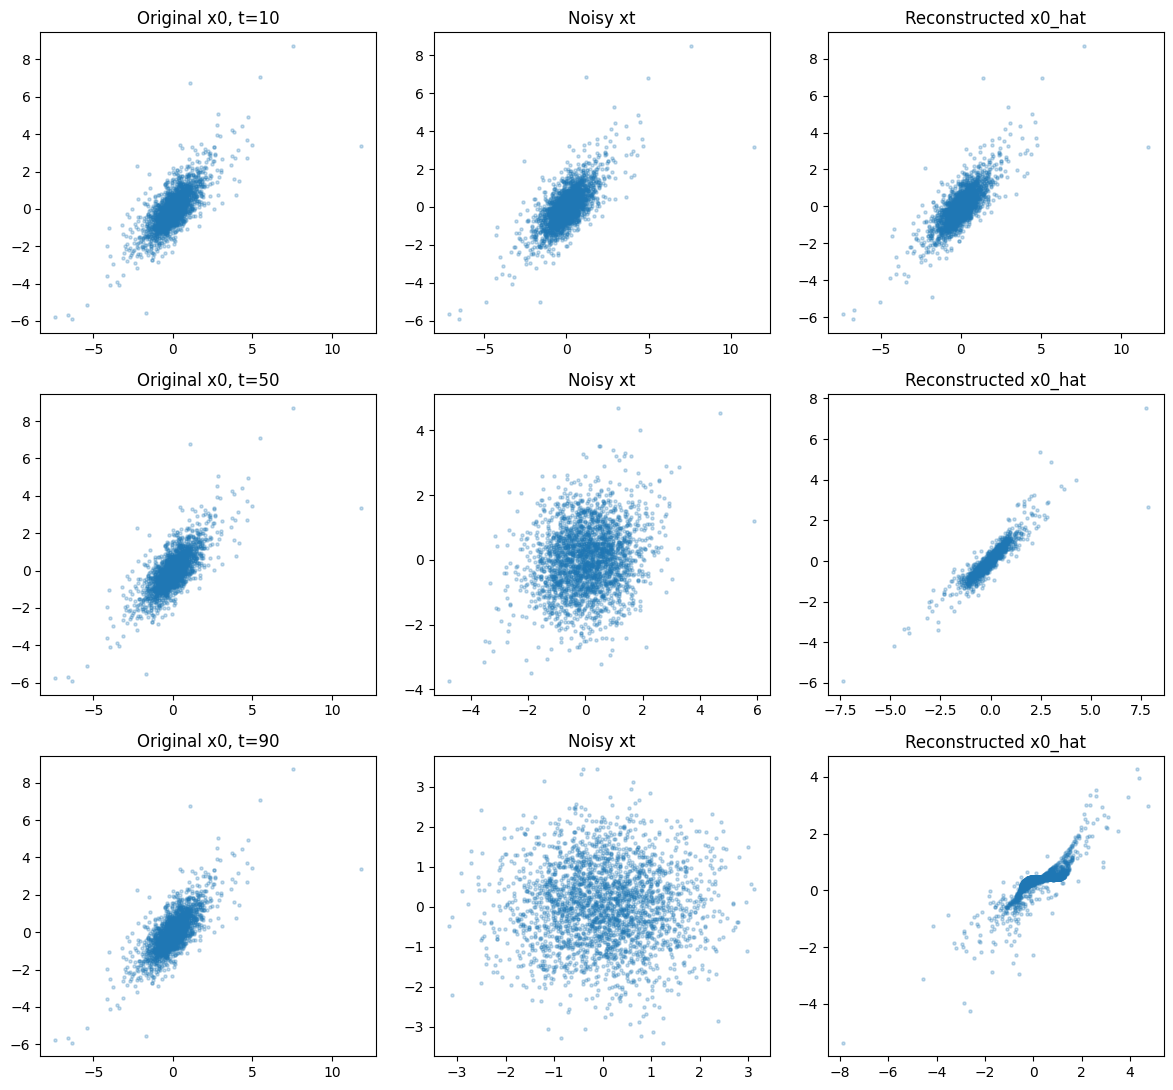

In [13]:
model.eval()

reconstruction_steps = [9, 49, 89]

fig, axes = plt.subplots(
    len(reconstruction_steps),
    3,
    figsize=(12, 11),
)

reconstruction_generator = torch.Generator().manual_seed(
    SEED + 3
)

base_noise = torch.randn(
    x0.shape,
    generator=reconstruction_generator,
)

for row, t_value in enumerate(reconstruction_steps):
    t_batch = torch.full(
        (len(x0),),
        t_value,
        dtype=torch.long,
    )

    xt, _ = q_sample(
        x0,
        t_batch,
        base_noise,
    )

    xhat = reconstruct_x0(
        model,
        xt.to(device),
        t_batch.to(device),
    )

    original = x0.numpy()
    noisy = xt.numpy()
    recovered = xhat.cpu().numpy()

    axes[row, 0].scatter(
        original[:, 0],
        original[:, 1],
        s=5,
        alpha=0.25,
    )

    axes[row, 1].scatter(
        noisy[:, 0],
        noisy[:, 1],
        s=5,
        alpha=0.25,
    )

    axes[row, 2].scatter(
        recovered[:, 0],
        recovered[:, 1],
        s=5,
        alpha=0.25,
    )

    axes[row, 0].set_title(
        f"Original x0, t={t_value + 1}"
    )

    axes[row, 1].set_title(
        "Noisy xt"
    )

    axes[row, 2].set_title(
        "Reconstructed x0_hat"
    )

fig.tight_layout()
plt.show()


### Assignment 2 — What Did the Model Learn?

**Q2-1.** Training loss가 감소한다는 것은 neural network가 무엇을
학습하고 있다는 뜻입니까?

**Q2-2.** \(t\)가 커질수록 개별 \(x_0\)의 정확한 복원이 어려워지는
이유를 설명하세요.

다음 두 관점을 함께 생각해 보세요.

1. \(x_t\)가 포함하는 원래 관측치 정보의 감소
2. 다음 항에 의한 noise-prediction error의 증폭

$$
\frac{1}{\sqrt{\bar{\alpha}_t}}
$$

즉, \(t\)가 커져 \(\bar{\alpha}_t\)가 작아지면 작은 noise prediction error도
\(\hat{x}_0\) 계산 과정에서 크게 확대될 수 있습니다.

**[YOUR ANSWER]**

**Q2-1. loss 감소의 의미**

- 학습 loss는 $E\left[\|\epsilon-\epsilon_\theta(x_t,t)\|^2\right]$, 즉 forward process에서 섞은 noise $\epsilon$과 모델이 예측한 noise $\epsilon_\theta(x_t,t)$의 평균제곱오차입니다. loss가 감소한다는 것은 모델이 **"이 $x_t$에는 어떤 noise가 섞여 있는가"를 점점 더 잘 맞히고 있다**는 뜻입니다. 데이터 $x_0$ 자체를 외우거나 직접 예측하는 것이 아니라, 각 noise level $t$에서 제거해야 할 noise를 배우는 것입니다.
- 이번 실행에서 처음 100 step의 평균 loss는 0.519였고 마지막 100 step의 평균 loss는 0.333으로 줄었습니다. noise를 전혀 모르고 0으로 예측하면 loss가 약 1이므로, 모델이 noise에 대한 정보를 실제로 학습했다고 볼 수 있습니다.
- 다만 loss가 0까지 내려가지는 않고 0.33 근처에서 머물렀습니다(500 step마다 출력된 값이 0.35~0.37). 이것은 학습이 잘못되었다는 뜻이 아니라, $t$가 작을 때는 섞인 noise가 매우 작아서 $x_t$에서 데이터와 noise를 구분하기 어렵고, 같은 $x_t$를 만들 수 있는 $\epsilon$이 여러 개이기 때문에 줄일 수 없는 오차가 남기 때문입니다. 또한 배치마다 $t$를 랜덤하게 뽑기 때문에 loss 값이 매 step 조금씩 흔들립니다.
- 이 noise 예측 능력이 있어야 Part 3에서 noise에서 시작해 한 단계씩 noise를 제거하며 금융수익률 분포를 생성할 수 있습니다.

**Q2-2. $t$가 커질수록 복원이 어려워지는 이유**

복원식은 다음과 같습니다.

$$
\hat{x}_0
=
\frac{
x_t-\sqrt{1-\bar{\alpha}_t}\,\epsilon_\theta(x_t,t)
}{
\sqrt{\bar{\alpha}_t}
}
$$

1. **$x_t$에 남은 원래 정보의 감소:** $x_t=\sqrt{\bar{\alpha}_t}x_0+\sqrt{1-\bar{\alpha}_t}\epsilon$에서 $t$가 커지면 신호 항의 계수 $\sqrt{\bar{\alpha}_t}$가 작아지고 noise 항이 지배적이 됩니다. 이 설정에서 $t=100$일 때 $\bar{\alpha}_T\approx0.0056$이므로 $x_t$에는 원래 관측치의 정보가 거의 남지 않습니다. 그러면 같은 $x_t$를 만들 수 있는 $x_0$가 매우 많아지므로, 모델은 개별 $x_0$ 하나가 아니라 가능한 $x_0$들의 평균에 가까운 값을 내놓게 됩니다.
2. **$1/\sqrt{\bar{\alpha}_t}$에 의한 오차 증폭:** 복원식에서 noise 예측 오차는 $\sqrt{1-\bar{\alpha}_t}/\sqrt{\bar{\alpha}_t}$ 배로 $\hat{x}_0$에 전달됩니다. $t=100$에서는 $1/\sqrt{\bar{\alpha}_T}\approx13$배이므로 작은 예측 오차도 크게 확대됩니다.

실제 결과도 이와 일치합니다.
- $t=10$에서는 $x_t$가 원본과 거의 같고 복원 결과도 원본과 거의 겹쳐서 극단값(꼬리)까지 살아 있습니다.
- $t=50$에서는 $x_t$가 둥근 구름처럼 되었고, 복원 결과는 원본보다 훨씬 얇은 대각선 모양으로 뭉쳤습니다.
- $t=90$에서는 $x_t$가 거의 순수한 Gaussian noise가 되었고, 복원 결과는 가운데가 좁은 띠 모양으로 무너져 원본의 분산 구조를 되살리지 못했습니다.

따라서 큰 $t$에서는 한 번에 $x_0$를 복원할 수 없고, 작은 단계씩 noise를 제거하는 reverse diffusion이 필요합니다.


# Part 3. Reverse Diffusion

## Gaussian noise에서 금융수익률 분포로

이제 forward process를 반대로 진행합니다.

시작점은 순수 Gaussian noise입니다.

$$
x_T\sim N(0,I)
$$

학습된 neural network가 각 단계에서 noise를 예측하고,
그 noise를 제거하면서

$$
x_T
\rightarrow
x_{T-1}
\rightarrow
\cdots
\rightarrow
x_1
\rightarrow
x_0
$$

로 이동합니다.

교육용 reverse step은 다음과 같습니다.

$$
x_{t-1}
=
\frac{1}{\sqrt{\alpha_t}}
\left(
x_t
-
\frac{\beta_t}
{\sqrt{1-\bar{\alpha}_t}}
\epsilon_\theta(x_t,t)
\right)
+
\sigma_t z
$$

여기서

$$
z\sim N(0,I)
$$

이고 이번 Week 03에서는 구현을 단순화하기 위해

$$
\sigma_t^2=\beta_t
$$

로 설정합니다.

마지막 reverse step에서는 새로운 noise를 추가하지 않으므로

$$
z=0
$$

으로 둡니다.

### 핵심 직관

Forward diffusion:

$$
\text{structured financial distribution}
\rightarrow
\text{Gaussian noise}
$$

Reverse diffusion:

$$
\text{Gaussian noise}
\rightarrow
\text{learned financial distribution}
$$

입니다.


In [14]:
@torch.no_grad()
def p_sample(model, xt, t_index, z=None):
    batch_size = xt.shape[0]

    t = torch.full(
        (batch_size,),
        t_index,
        device=xt.device,
        dtype=torch.long,
    )

    beta_t = betas.to(xt.device)[t_index]
    alpha_t = alphas.to(xt.device)[t_index]
    alpha_bar_t = alpha_bars.to(xt.device)[t_index]

    pred_noise = model(xt, t)

    # TODO 11
    # DDPM reverse mean을 구현하세요.
    mean = (
        xt - beta_t / torch.sqrt(1.0 - alpha_bar_t) * pred_noise
    ) / torch.sqrt(alpha_t)

    if t_index == 0:
        return mean

    if z is None:
        z = torch.randn_like(xt)

    # Week 03 convention:
    # sigma_t^2 = beta_t
    return mean + torch.sqrt(beta_t) * z


In [15]:
@torch.no_grad()
def sample_reverse(
    model,
    n_samples,
    seed,
    save_steps=(99, 74, 49, 24, 0),
):
    generator = torch.Generator(
        device=device
    ).manual_seed(seed)

    xt = torch.randn(
        (n_samples, 2),
        generator=generator,
        device=device,
    )

    snapshots = {
        T: xt.detach().cpu().numpy()
    }

    model.eval()

    for t_index in reversed(range(T)):
        if t_index == 0:
            z = torch.zeros_like(xt)
        else:
            z = torch.randn(
                xt.shape,
                generator=generator,
                device=device,
            )

        xt = p_sample(
            model,
            xt,
            t_index,
            z=z,
        )

        if t_index in save_steps:
            snapshots[t_index] = (
                xt.detach().cpu().numpy()
            )

    return xt.detach().cpu().numpy(), snapshots


generated, reverse_snapshots = sample_reverse(
    model,
    n_samples=len(x0),
    seed=SEED + 10,
)

print("Generated shape:", generated.shape)


Generated shape: (2631, 2)


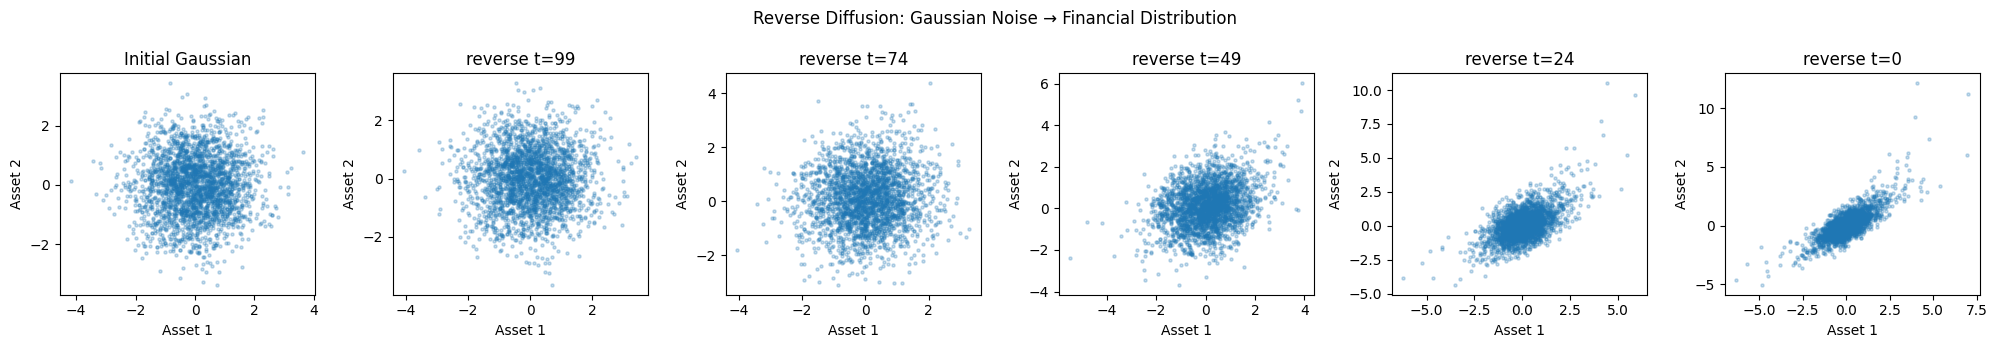

In [16]:
snapshot_order = [T, 99, 74, 49, 24, 0]

fig, axes = plt.subplots(
    1,
    len(snapshot_order),
    figsize=(20, 3.5),
)

for ax, step in zip(
    axes,
    snapshot_order,
):
    arr = reverse_snapshots[step]

    ax.scatter(
        arr[:, 0],
        arr[:, 1],
        s=5,
        alpha=0.25,
    )

    if step == T:
        title = "Initial Gaussian"
    else:
        title = f"reverse t={step}"

    ax.set_title(title)
    ax.set_xlabel("Asset 1")
    ax.set_ylabel("Asset 2")

fig.suptitle(
    "Reverse Diffusion: Gaussian Noise → Financial Distribution"
)
fig.tight_layout()
plt.show()


# Part 4. Financial Evaluation

## Real vs. Gaussian vs. Diffusion

생성된 데이터가 단순히 그림상 비슷해 보인다는 것만으로는 충분하지 않습니다.

다음 세 분포를 금융통계 관점에서 비교합니다.

$$
\boxed{
\text{Original Financial Distribution}
\quad vs.\quad
\text{Gaussian}
\quad vs.\quad
\text{Diffusion}
}
$$

여기서 `Real`은 오늘 실습에서 **Diffusion이 학습해야 하는 원래 금융수익률 분포**
를 의미합니다. 특정 실제 기업의 시장자료라는 의미는 아닙니다.

Gaussian baseline은 원래 데이터의 표본 평균과 공분산을 이용하여 적합한

$$
N(\hat{\mu},\hat{\Sigma})
$$

입니다.

### 비교할 금융통계

- Correlation
- Excess kurtosis
- 1% return quantile
- Joint downside probability

Joint downside probability는 두 자산이 각각 원래 데이터의
5% quantile보다 동시에 낮을 확률로 정의합니다.

이 비교의 핵심 질문은 다음과 같습니다.

> 평균과 공분산을 이용하는 Gaussian model과 비교했을 때,
> Diffusion model은 fat tail과 joint downside 같은
> 비정규적 분포 특성을 얼마나 학습할 수 있는가?


In [17]:
def financial_metrics(
    samples,
    q05_reference=None,
):
    samples = np.asarray(samples)

    corr = np.corrcoef(
        samples.T
    )[0, 1]

    kurt1 = excess_kurtosis(
        samples[:, 0]
    )

    kurt2 = excess_kurtosis(
        samples[:, 1]
    )

    q01_1 = np.quantile(
        samples[:, 0],
        0.01,
    )

    q01_2 = np.quantile(
        samples[:, 1],
        0.01,
    )

    if q05_reference is None:
        q05_reference = np.quantile(
            samples,
            0.05,
            axis=0,
        )

    joint_downside = np.mean(
        (samples[:, 0] < q05_reference[0])
        &
        (samples[:, 1] < q05_reference[1])
    )

    return {
        "correlation": corr,
        "excess_kurtosis_1": kurt1,
        "excess_kurtosis_2": kurt2,
        "q01_return_1": q01_1,
        "q01_return_2": q01_2,
        "joint_downside": joint_downside,
    }


real_q05 = np.quantile(
    x0_np,
    0.05,
    axis=0,
)

real_metrics = financial_metrics(
    x0_np,
    q05_reference=real_q05,
)

pd.Series(
    real_metrics,
    name="Real",
)


correlation           0.755927
excess_kurtosis_1    13.446659
excess_kurtosis_2     7.253052
q01_return_1         -2.705128
q01_return_2         -2.438230
joint_downside        0.025086
Name: Real, dtype: float64

In [18]:
gaussian_rng = np.random.default_rng(
    SEED + 20
)

gaussian_mean = x0_np.mean(axis=0)
gaussian_cov = np.cov(
    x0_np.T,
    ddof=1,
)

gaussian_sample = (
    gaussian_rng.multivariate_normal(
        gaussian_mean,
        gaussian_cov,
        size=len(x0_np),
    )
)

gaussian_metrics = financial_metrics(
    gaussian_sample,
    q05_reference=real_q05,
)

print(
    pd.Series(
        gaussian_metrics,
        name="Gaussian",
    )
)


correlation          0.748751
excess_kurtosis_1    0.145836
excess_kurtosis_2   -0.062721
q01_return_1        -2.330218
q01_return_2        -2.299054
joint_downside       0.036108
Name: Gaussian, dtype: float64


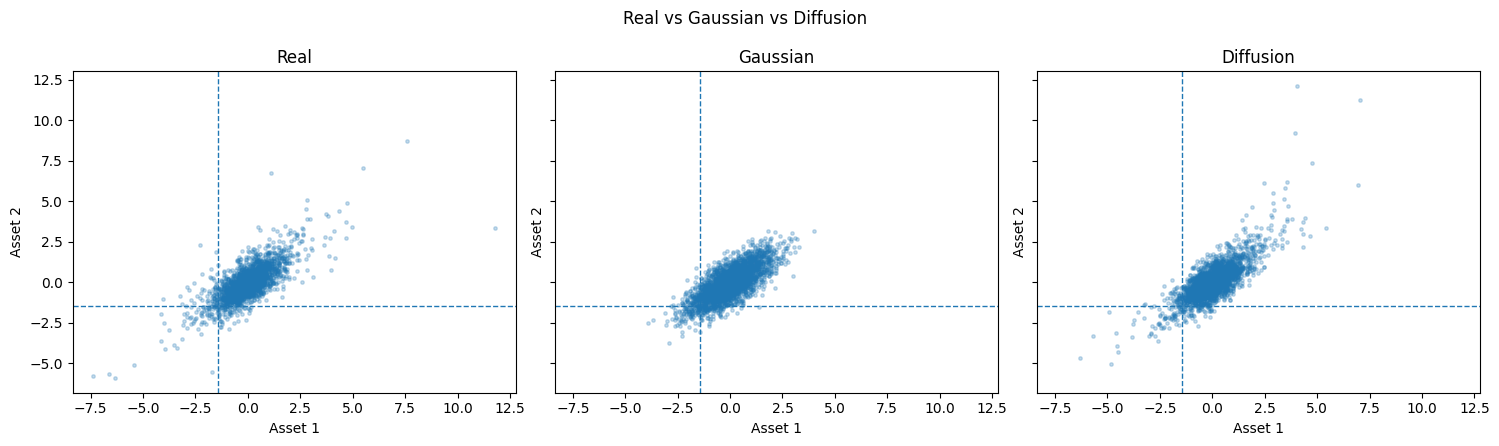

In [19]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.5),
    sharex=True,
    sharey=True,
)

datasets = [
    ("Real", x0_np),
    ("Gaussian", gaussian_sample),
    ("Diffusion", generated),
]

for ax, (name, arr) in zip(
    axes,
    datasets,
):
    ax.scatter(
        arr[:, 0],
        arr[:, 1],
        s=6,
        alpha=0.25,
    )

    ax.axvline(
        real_q05[0],
        linestyle="--",
        linewidth=1,
    )

    ax.axhline(
        real_q05[1],
        linestyle="--",
        linewidth=1,
    )

    ax.set_title(name)
    ax.set_xlabel("Asset 1")
    ax.set_ylabel("Asset 2")

fig.suptitle(
    "Real vs Gaussian vs Diffusion"
)
fig.tight_layout()
plt.show()


## Sampling Uncertainty

생성 샘플을 한 번만 비교하면 결과가 우연한 sampling noise에 영향을
받을 수 있습니다.

따라서 원래 데이터와 동일한 크기의 표본을 여러 번 생성하여
각 통계량의 평균과 변동 범위를 비교합니다.

이번 실습에서는

$$
R=20
$$

회 반복 생성합니다.

각 통계량에 대해 평균과 5%–95% 범위를 계산하여
Gaussian model과 Diffusion model의 생성 결과가 얼마나 안정적인지
확인합니다.


In [20]:
R = 20
n_eval = len(x0_np)

gaussian_runs = []
diffusion_runs = []

for repetition in range(R):
    local_rng = np.random.default_rng(
        SEED + 100 + repetition
    )

    g_sample = (
        local_rng.multivariate_normal(
            gaussian_mean,
            gaussian_cov,
            size=n_eval,
        )
    )

    gaussian_runs.append(
        financial_metrics(
            g_sample,
            q05_reference=real_q05,
        )
    )

    d_sample, _ = sample_reverse(
        model,
        n_samples=n_eval,
        seed=SEED + 1000 + repetition,
        save_steps=(),
    )

    diffusion_runs.append(
        financial_metrics(
            d_sample,
            q05_reference=real_q05,
        )
    )

gaussian_runs_df = pd.DataFrame(
    gaussian_runs
)

diffusion_runs_df = pd.DataFrame(
    diffusion_runs
)

print(
    "Repeated sampling completed:",
    R,
    "runs",
)


Repeated sampling completed: 20 runs


In [21]:
def summarize_runs(df):
    summary = pd.DataFrame(
        {
            "mean": df.mean(),
            "p05": df.quantile(0.05),
            "p95": df.quantile(0.95),
        }
    )

    return summary


gaussian_summary = summarize_runs(
    gaussian_runs_df
)

diffusion_summary = summarize_runs(
    diffusion_runs_df
)

comparison_rows = []

for metric in real_metrics:
    comparison_rows.append(
        {
            "metric": metric,
            "real": real_metrics[metric],
            "gaussian_mean": (
                gaussian_summary.loc[
                    metric,
                    "mean",
                ]
            ),
            "gaussian_p05": (
                gaussian_summary.loc[
                    metric,
                    "p05",
                ]
            ),
            "gaussian_p95": (
                gaussian_summary.loc[
                    metric,
                    "p95",
                ]
            ),
            "diffusion_mean": (
                diffusion_summary.loc[
                    metric,
                    "mean",
                ]
            ),
            "diffusion_p05": (
                diffusion_summary.loc[
                    metric,
                    "p05",
                ]
            ),
            "diffusion_p95": (
                diffusion_summary.loc[
                    metric,
                    "p95",
                ]
            ),
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

display(
    comparison_table.round(4)
)


,metric,real,gaussian_mean,gaussian_p05,gaussian_p95,diffusion_mean,diffusion_p05,diffusion_p95
0,correlation,0.7559,0.7544,0.7474,0.7643,0.7765,0.7548,0.8045
1,excess_kurtosis_1,13.4467,-0.0275,-0.1436,0.0664,17.2896,6.6185,37.3950
2,excess_kurtosis_2,7.2531,-0.0473,-0.1687,0.0800,17.2044,5.3336,44.2117
3,q01_return_1,-2.7051,-2.3147,-2.4377,-2.2140,-2.5024,-2.7800,-2.2601
4,q01_return_2,-2.4382,-2.3372,-2.4139,-2.2503,-2.4312,-2.5939,-2.2724
5,joint_downside,0.0251,0.0346,0.0293,0.0380,0.0254,0.0205,0.0305


# Final Assignment

지금까지 생성한 **자신의 실행 결과**를 근거로 다음 질문에 답하세요.

일반적인 Diffusion model 설명만 쓰는 것이 아니라,
위에서 계산한 표와 그림의 실제 결과를 인용하여 설명해야 합니다.

---

### Q1. Gaussian baseline

Gaussian baseline은 원래 두 자산 수익률의 어떤 특성을 잘 재현하고,
어떤 특성을 제대로 재현하지 못합니까?

Correlation, excess kurtosis, downside tail 가운데
최소 두 개 이상의 결과를 근거로 설명하세요.

**[YOUR ANSWER]**

**잘 재현하는 것: 상관관계(평균과 공분산으로 정해지는 특성)**

- Gaussian baseline은 원래 데이터의 표본 평균과 공분산으로 만든 $N(\hat{\mu},\hat{\Sigma})$이므로, 2차 모멘트인 상관관계는 거의 그대로 재현합니다. 원래 상관계수는 0.7559, Gaussian 20회 반복의 평균은 0.7544(5%~95% 범위 0.7474~0.7643)로 원래 값이 범위 안에 있습니다.

**제대로 재현하지 못하는 것: fat tail**

- **Excess kurtosis:** 원래 데이터는 Asset 1이 13.4467, Asset 2가 7.2531로 정규분포(0)보다 꼬리가 매우 두껍습니다. 반면 Gaussian은 평균이 각각 -0.0275, -0.0473이고 범위도 -0.17~0.08에 머물러 거의 0입니다. 원래 값이 Gaussian의 범위에서 완전히 벗어나 있습니다.
- **1% quantile(하방 꼬리):** Asset 1에서 원래 값은 -2.7051인데 Gaussian은 평균 -2.3147(범위 -2.4377~-2.2140)입니다. 원래 값이 범위 밖이므로 Gaussian은 하방 극단 손실을 과소평가합니다. Asset 2는 원래 -2.4382, Gaussian 평균 -2.3372(범위 -2.4139~-2.2503)로 차이가 더 작지만 같은 방향입니다.
- **Joint downside probability:** 원래 값은 0.0251인데 Gaussian 평균은 0.0346(범위 0.0293~0.0380)으로 원래 값이 범위 밖입니다. 두 자산이 동시에 하위 5% 아래로 내려가는 확률을 이 설정에서는 오히려 높게 추정했습니다. 이유는 기준선인 `real_q05`에 있습니다. 원래 데이터는 fat tail이면서 분산이 1로 표준화되어 있어 질량이 중심부에 몰려 있고, 그 결과 5% quantile이 Asset 1은 -1.444, Asset 2는 -1.471로 정규분포의 -1.645보다 덜 극단적입니다. 이 기준선을 분산이 같은 Gaussian 샘플에 적용하면 각 자산이 기준 아래로 떨어질 확률이 5%가 아니라 이론적으로 약 7.4%, 7.1%가 되어, 동시 하락 확률도 함께 커집니다.

정리하면 Gaussian은 평균과 공분산(상관)만 맞출 수 있고, 두꺼운 꼬리와 같은 비정규적 특성은 구조적으로 만들 수 없습니다.

---

### Q2. Diffusion model

Diffusion model은 Gaussian baseline과 비교하여
원래 금융수익률의 어떤 분포적 특성을 더 잘 또는 더 못 재현합니까?

자신의 `comparison_table` 결과를 이용하여 설명하세요.

**[YOUR ANSWER]**

**더 잘 재현하는 것**

- **Fat tail:** Diffusion의 excess kurtosis 평균은 Asset 1이 17.29, Asset 2가 17.20으로 0 근처인 Gaussian(-0.03, -0.05)과 달리 원래 데이터(13.45, 7.25)처럼 두꺼운 꼬리를 만들어 냅니다. 두 원래 값은 모두 Diffusion의 5%~95% 범위(Asset 1은 6.62~37.40, Asset 2는 5.33~44.21) 안에 들어 있습니다.
- **1% quantile:** Asset 1에서 Diffusion 평균은 -2.5024로 원래 값 -2.7051에 Gaussian(-2.3147)보다 가깝고, 범위(-2.7800~-2.2601)에 원래 값이 들어 있습니다. Asset 2는 Diffusion 평균 -2.4312로 원래 값 -2.4382와 거의 같습니다.
- **Joint downside:** 원래 값 0.0251에 대해 Diffusion 평균은 0.0254로 거의 일치하고 범위(0.0205~0.0305) 안에 있습니다. Gaussian(0.0346)은 이 범위를 벗어났습니다.

**더 못하거나 불안정한 것**

- **Excess kurtosis의 크기와 변동:** Diffusion의 첨도 평균(17.29, 17.20)은 원래 값보다 큽니다. 특히 Asset 2는 원래 7.25의 두 배 이상이고, 5%~95% 범위가 매우 넓습니다(Asset 1: 6.62~37.40, Asset 2: 5.33~44.21). 생성할 때마다 극단값이 몇 개 나오느냐에 따라 첨도가 크게 달라지는 불안정한 통계량이라는 뜻입니다. 꼬리의 존재는 재현했지만 크기는 정확하지 않습니다.
- **상관관계:** Diffusion 평균은 0.7765(범위 0.7548~0.8045)로 원래 값 0.7559가 범위의 하단 경계에 있습니다. 상관관계만 보면 Gaussian(0.7544)이 더 정확합니다.

정리하면 Diffusion은 평균과 공분산만 맞추는 Gaussian이 만들 수 없는 fat tail, 하방 꼬리, 동시 하락 확률을 상당 부분 재현하지만, 상관관계는 Gaussian보다 약간 부정확하고 첨도는 크기가 과대하며 변동이 큽니다.

---

### Q3. 이 모델의 한계

이번 실습의 Diffusion model이 실제 금융시장의 완전한
scenario generator라고 할 수 없는 이유는 무엇입니까?

특히 이번 모델이 각 날짜의

$$
(r_{1,t},r_{2,t})
$$

를 독립적인 observation처럼 학습했다는 점을 고려하세요.

실제 금융시장에서 중요한

- time-series dependence
- volatility clustering
- regime change
- 데이터에서 충분히 관측되지 않은 극단적 tail event

등의 관점에서 설명하세요.

**[YOUR ANSWER]**

이번 모델은 2631일의 $(r_{1,t},r_{2,t})$를 날짜 순서와 상관없이 섞어 놓은 점들의 집합처럼 학습했습니다(학습 루프에서 `torch.randint`로 임의의 행을 뽑았습니다). 따라서 **하루의 두 자산 결합분포**는 재현할 수 있지만, 시간 축에서의 구조는 전혀 배우지 않습니다.

- **Time-series dependence:** 어제의 수익률이 오늘의 수익률에 미치는 영향(자기상관, 추세, 반전)을 모델은 알지 못합니다. 생성된 각 샘플은 서로 독립이어서, 연속된 날짜의 경로(path)를 만들 수 없습니다. 그래서 며칠에 걸친 누적 손실이나 최대낙폭(drawdown) 같은 경로 의존적 위험은 평가할 수 없습니다.
- **Volatility clustering:** 실제 시장은 변동성이 큰 날 뒤에 큰 날이 이어지는 경향이 있습니다. 이 모델은 날짜를 독립으로 취급하므로 큰 변동이 몰려서 나타나는 현상을 만들지 못합니다. 첨도(fat tail)는 재현해도, 그 꼬리가 시간상 어떻게 군집하는지는 알 수 없습니다.
- **Regime change:** 위기, 금리 인상기 같은 시장 국면이 바뀌면 분포 자체가 바뀝니다. 이 모델은 2016~2026년 전체 기간을 하나의 고정된 분포로 학습했기 때문에, "지금이 어떤 국면인가"에 따라 달라지는 조건부 분포를 만들 수 없습니다.
- **관측되지 않은 극단적 tail event:** 모델은 학습 데이터에서 본 분포를 따라 생성합니다. 데이터에 없던 규모의 충격은 생성하기 어렵고, 반대로 이번 결과처럼 첨도가 원래 값보다 크고 반복마다 크게 달라지는 것(5%~95% 범위가 6.6~37.4)은 꼬리 부분의 신뢰도가 낮다는 뜻입니다. 극단 손실을 정확히 추정하는 위험관리 용도로는 한계가 있습니다.

그래서 이 모델은 "주어진 기간의 하루 수익률 분포를 닮은 샘플을 만드는 생성기"일 뿐, 시간에 따라 변하는 실제 시장의 시나리오를 완전히 만들어 내는 scenario generator는 아닙니다. 이를 보완하려면 날짜 순서를 반영하는 시계열 구조(과거 수익률을 조건으로 사용하는 conditional diffusion 등)나 국면 정보를 모델에 넣어야 합니다.


# Submission Check

제출 전에 다음 사항을 확인하세요.

1. 모든 TODO 코드를 완성했는가?
2. Notebook을 위에서 아래까지 순서대로 실행했는가?
3. 오류가 발생한 셀이 없는가?
4. Assignment 1과 Assignment 2에 답했는가?
5. Final Assignment Q1–Q3에 답했는가?
6. `comparison_table`이 정상적으로 출력되는가?

### 제출 파일

완성된 **이 Notebook 한 개**를 제출합니다.

코드 실행 결과와 해석 답변이 모두 Notebook 안에 남아 있어야 합니다.


In [22]:
required_objects = [
    "betas",
    "alphas",
    "alpha_bars",
    "q_sample",
    "model",
    "losses",
    "reconstruct_x0",
    "p_sample",
    "generated",
    "comparison_table",
]

missing = [
    name
    for name in required_objects
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required objects: "
        + ", ".join(missing)
    )

assert len(losses) > 0
assert generated.shape[1] == 2
assert len(comparison_table) == 6

print(
    "DIFFUSION_WEEK03_LAB_ASSIGNMENT_PASS"
)


DIFFUSION_WEEK03_LAB_ASSIGNMENT_PASS
